# 08 — Explain the frozen model and cache dashboard inputs

**After completed Notebooks 06 and 07:** select the same project Python kernel and **Run All**. This continues the remembered run automatically; do not start 01 again just to add this stage. No model is fitted and no 01–07 file is changed.

**One-time dependency:** if SHAP is missing, run `%pip install -r requirements.txt` in a temporary cell, then restart the kernel. Restore the package versions recorded with an older saved model if requested; do not retrain to bypass a version error.

Explain the selected forecasting model, not Isolation Forest. Use a fixed random training sample for a descriptive feature summary and precompute explanations for up to 200 latest highest-score rows. All supported latest rows remain available to the dashboard; rows without a cached explanation are explicitly marked.

SHAP describes this model's associations, not causal price drivers, verified source errors or affordability benefits. The model score remains **uncalibrated**, and the latest week is a historical snapshot within the configured data scope.

## 1. Continue the same completed experiment
Verify both checkpoints and the frozen prepared files. Read only current/past features and identifiers. Forecast scores/alerts must match 06; anomaly scores/flags must match 07. A changed upstream file stops execution rather than silently mixing runs.

In [1]:
import hashlib
import json
from importlib import metadata, reload
from pathlib import Path
from time import perf_counter

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit

import pricecatcher_config as cfg
cfg = reload(cfg)
MODEL_DIR = next((folder for folder in cfg.MODEL_DIRS
                  if any((folder / name).exists() for name in ["best_model.joblib", "model_manifest.json"])), None)
if MODEL_DIR is None:
    raise FileNotFoundError("Finish Notebook 06 first, then Run All in 07 and 08. Do not restart 01 to reopen this run.")
PREPARED_DIR = cfg.PROJECT_ROOT / "experiments" / "holdout" / "05_modelling"
ANOMALY_DIR = cfg.PROJECT_ROOT / "07_anomalies"
OUTPUT_DIR = cfg.PROJECT_ROOT / "08_explanations"
KEYS = ["item_code", "state", "district", "premise_type", "week_start"]
print("Run folder:", cfg.PROJECT_ROOT)
print("Explanation outputs:", OUTPUT_DIR)


Run folder: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240
Explanation outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/08_explanations


## Small reusable calculations
Use the exact saved preprocessing: categorical values are converted to strings as in 06, and numeric missing values are handled by the frozen imputer. Expanded one-hot and missing-indicator contributions are **summed** back to original feature names; this display grouping preserves additivity but does not create a causal interpretation or a new jointly grouped SHAP game.

In [2]:
def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()


def model_inputs(frame, settings):
    result = frame[settings["feature_columns"]].copy()
    for name in settings["categorical_features"]:
        result[name] = result[name].astype("string").fillna("__missing__").astype(str)
    return result


def dense_matrix(matrix):
    # Keep the offline explanation batch modest even if category counts grow.
    if matrix.shape[0] * matrix.shape[1] > 2_000_000:
        raise ValueError("Explanation matrix is too large for this bounded cache. Review category counts before changing the protocol.")
    return matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix)


def source_features(preprocess, settings):
    numeric = preprocess.named_transformers_["numeric"].named_steps["impute"]
    names = [str(name).removeprefix("missingindicator_")
             for name in numeric.get_feature_names_out(settings["numeric_features"])]
    encoder = preprocess.named_transformers_["categorical"]
    if encoder.drop is not None or encoder.min_frequency is not None or encoder.max_categories is not None:
        raise ValueError("This cache expects the unchanged one-hot encoder from 06.")
    for name, categories in zip(settings["categorical_features"], encoder.categories_):
        names.extend([name] * len(categories))
    if not set(names).issubset(settings["feature_columns"]):
        raise ValueError("Cannot map the frozen preprocessing back to original features.")
    return names


def explain_rows(pipeline, family, frame, background, settings, explainer=None):
    """Return grouped SHAP, its baseline, raw output and the unchanged model score."""
    features = settings["feature_columns"]
    if frame.empty:
        return np.empty((0, len(features))), np.array([]), np.array([]), np.array([]), explainer
    X = model_inputs(frame, settings)
    preprocess, estimator = pipeline.named_steps["preprocess"], pipeline.named_steps["model"]
    matrix = preprocess.transform(X)
    names = source_features(preprocess, settings)
    if len(names) != matrix.shape[1] or list(estimator.classes_) != [0, 1]:
        raise ValueError("Expected the frozen binary 0/1 model and matching transformed features.")
    if family == "XGBoost":
        # Native TreeSHAP preserves CSR implicit-zero/missing semantics used in 06.
        import xgboost as xgb
        contributions = estimator.get_booster().predict(xgb.DMatrix(matrix), pred_contribs=True)
        values, base = contributions[:, :-1], contributions[:, -1]
        raw = estimator.predict(matrix, output_margin=True)
    else:
        import shap
        matrix = dense_matrix(matrix)
        if explainer is None:
            if family == "Logistic Regression":
                reference = dense_matrix(preprocess.transform(model_inputs(background, settings)))
                explainer = shap.LinearExplainer(estimator, reference)
            elif family in {"LightGBM", "Random Forest"}:
                explainer = shap.TreeExplainer(estimator, feature_perturbation="tree_path_dependent", model_output="raw")
            else:
                raise ValueError(f"Unsupported frozen model family: {family}")
        result = explainer(matrix)
        values, base = np.asarray(result.values), np.asarray(result.base_values)
        if values.ndim == 3:
            values = values[:, :, 1]
            base = base[:, 1] if base.ndim == 2 else base[1]
        base = np.broadcast_to(np.squeeze(base), (len(frame),)).copy()
        if family == "Logistic Regression":
            raw = estimator.decision_function(matrix)
        elif family == "LightGBM":
            raw = estimator.booster_.predict(matrix, raw_score=True)
        else:
            raw = estimator.predict_proba(matrix)[:, 1]
    grouped = np.column_stack([values[:, np.asarray(names) == name].sum(axis=1) for name in features])
    scores = pipeline.predict_proba(X)[:, 1]
    np.testing.assert_allclose(base + grouped.sum(axis=1), raw, rtol=1e-5, atol=1e-5)
    reconstructed = raw if family == "Random Forest" else expit(raw)
    np.testing.assert_allclose(reconstructed, scores, rtol=1e-5, atol=1e-6)
    return grouped, np.asarray(base), np.asarray(raw), scores, explainer


def anomaly_inputs(frame):
    """The six fixed version-1 formulas from 07; this does not fit a detector."""
    price = frame.weekly_median_price
    return pd.DataFrame({
        "current_change_pct": frame.weekly_price_change_pct,
        "change_2w_pct": 100 * (price / frame.lag_2w_price - 1),
        "change_4w_pct": 100 * (price / frame.lag_4w_price - 1),
        "deviation_4w_pct": 100 * (price / frame.rolling_mean_4w - 1),
        "within_week_variation_pct": 100 * frame.weekly_std_price / price,
        "history_variation_4w_pct": 100 * frame.rolling_std_4w / frame.rolling_mean_4w,
    }, index=frame.index)


def match_latest(frame, latest, name):
    """Align saved results to exactly the prepared latest series; never substitute old weeks."""
    if frame.duplicated(KEYS).any() or len(frame) != len(latest):
        raise ValueError(f"{name}: duplicate rows or different latest coverage. Rerun the matching completed stage.")
    aligned = latest[KEYS].merge(frame, on=KEYS, how="left", validate="one_to_one", indicator=True)
    if not aligned["_merge"].eq("both").all():
        raise ValueError(f"{name}: stale or mismatched latest rows.")
    return aligned.drop(columns="_merge")


In [3]:
main_paths = [MODEL_DIR / name for name in ["model_manifest.json", "selection.json", "best_model.joblib", "latest_predictions.parquet"]]
anomaly_paths = [ANOMALY_DIR / name for name in ["anomaly_manifest.json", "isolation_forest.joblib", "anomaly_scores.parquet"]]
missing = [str(path) for path in main_paths + anomaly_paths if not path.is_file()]
if missing:
    raise FileNotFoundError("Finish/restore the matching 06 and 07 outputs first: " + ", ".join(missing))
main_manifest = json.loads(main_paths[0].read_text())
selection = json.loads(main_paths[1].read_text())
if main_manifest.get("run_status", "completed") != "completed" or selection != main_manifest["selection"]:
    raise ValueError("06 is incomplete or its selection changed. Finish or restore it; 08 never retrains it.")
if file_hash(main_paths[2]) != main_manifest["model_sha256"]:
    raise ValueError("06 model changed. Restore the completed checkpoint.")
input_hashes = main_manifest["input_sha256"]
for filename in ["experiment_settings.json", "train.parquet", "latest_prediction_inputs.parquet"]:
    if f"holdout/{filename}" not in input_hashes:
        raise ValueError(f"Missing frozen 06 input record for {filename}.")
for relative, expected in input_hashes.items():
    experiment, filename = relative.split("/", 1)
    path = cfg.PROJECT_ROOT / "experiments" / experiment / "05_modelling" / filename
    if not path.is_file() or file_hash(path) != expected:
        raise ValueError(f"Frozen prepared input missing/changed: {path}. Restore it; nothing upstream is regenerated here.")
anomaly_manifest = json.loads(anomaly_paths[0].read_text())
if anomaly_manifest["frozen_inputs"] != {**input_hashes, "06_model_sha256": main_manifest["model_sha256"]}:
    raise ValueError("07 belongs to different frozen inputs. Restore the matching 07 checkpoint.")
if anomaly_manifest["protocol"]["schema_version"] != 1 or file_hash(anomaly_paths[1]) != anomaly_manifest["model_sha256"]:
    raise ValueError("07 detector changed or has an unsupported protocol.")
for label, manifest in [("06", main_manifest), ("07", anomaly_manifest)]:
    if manifest["package_versions"]["scikit-learn"] != metadata.version("scikit-learn"):
        raise ValueError(f"Restore the scikit-learn version in {label}'s manifest before loading its model.")
settings = json.loads((PREPARED_DIR / "experiment_settings.json").read_text())
FEATURES = settings["feature_columns"]
IDENTIFIERS = cfg.GROUP_KEYS + ["week_start", "next_week_end"]
COLUMNS = list(dict.fromkeys(IDENTIFIERS + FEATURES))
latest = pd.read_parquet(PREPARED_DIR / "latest_prediction_inputs.parquet", columns=COLUMNS)
end = pd.Timestamp(settings["evaluation_end"])
expected_week = end - pd.Timedelta(days=(end.dayofweek + 1) % 7 + 6)
if latest[KEYS].isna().any().any() or not latest.week_start.eq(expected_week).all():
    raise ValueError("Prepared latest inputs are missing identifiers or use stale weeks.")
forecast_model = joblib.load(main_paths[2])
anomaly_model = joblib.load(anomaly_paths[1])
family = selection["family"]
units = "uncalibrated model-score units" if family == "Random Forest" else "model log-odds"
print("Verified selected model:", selection["candidate"], "| Explanation units:", units)
print("Latest complete week:", expected_week.date(), "| Supported rows:", len(latest))


Verified selected model: lgb_leaves31 | Explanation units: model log-odds
Latest complete week: 2026-06-22 | Supported rows: 5343


## 2. Keep the forecasting and anomaly scores separate
All supported latest observations remain in the dashboard file. An anomaly flag is not a surge prediction or a confirmed source error. Unrepresented districts/series must be displayed as unsupported, not as zero risk.

Recompute only current scores from the verified, already fitted pipelines to check the saved exports. No labels, future outcomes, fitting or cutoff selection occur.

In [4]:
forecasts = match_latest(pd.read_parquet(main_paths[3], columns=KEYS + ["model_score", "predicted_surge"]), latest, "06 predictions")
anomalies = match_latest(pd.read_parquet(anomaly_paths[2], filters=[("split", "==", "latest")],
    columns=KEYS + ["anomaly_score", "is_anomaly"]), latest, "07 anomalies")
if len(latest):
    expected_scores = forecast_model.predict_proba(model_inputs(latest, settings))[:, 1]
    np.testing.assert_allclose(forecasts.model_score, expected_scores, rtol=1e-6, atol=1e-8)
    np.testing.assert_array_equal(forecasts.predicted_surge, expected_scores >= selection["score_cutoff"])
    X_anomaly = anomaly_inputs(latest)
    if list(anomaly_manifest["protocol"]["feature_formulas"]) != list(X_anomaly.columns):
        raise ValueError("07 feature definitions differ from the supported version-1 detector.")
    if not np.isclose(-anomaly_model.named_steps["detector"].offset_, anomaly_manifest["training_score_threshold"], rtol=0, atol=1e-12):
        raise ValueError("07 training threshold differs from its saved detector.")
    np.testing.assert_allclose(anomalies.anomaly_score, -anomaly_model.score_samples(X_anomaly), rtol=1e-6, atol=1e-8)
    np.testing.assert_array_equal(anomalies.is_anomaly, anomaly_model.predict(X_anomaly) == -1)
dashboard = latest.copy()
for name in ["model_score", "predicted_surge"]:
    dashboard[name] = forecasts[name].to_numpy()
for name in ["anomaly_score", "is_anomaly"]:
    dashboard[name] = anomalies[name].to_numpy()
dashboard = dashboard.sort_values(["model_score"] + KEYS, ascending=[False] + [True] * len(KEYS)).reset_index(drop=True)
dashboard["forecast_id"] = [f"latest_{i:05d}" for i in range(len(dashboard))]


## 3. Declare a bounded offline cache
Use up to **200 randomly sampled training rows** (seed 42) for the descriptive feature summary, and up to **200 highest-score latest rows** for local explanations. The latter is a prioritised subset and must not be called representative global importance. A linear model uses up to 100 training rows for its independent-feature background. Tree models use TreeSHAP's training path/leaf reference; XGBoost uses its native TreeSHAP to preserve sparse-input semantics.

Do not interpret correlated lags or grouped one-hot columns as independent economic causes. Log-odds contributions are not percentage-point changes in event probability. Random Forest's raw contributions instead reconstruct its uncalibrated positive-class score.

Only this derived 08 cache may be regenerated if its files/settings change. Frozen models and inputs always remain protected. A complete matching cache is loaded without recomputing SHAP.

In [5]:
try:
    shap_version = metadata.version("shap")
except metadata.PackageNotFoundError:
    raise ModuleNotFoundError("SHAP is missing. Run %pip install -r requirements.txt in a temporary notebook cell, then restart and Run All.")
protocol = {"schema_version": 1, "reference_rows": 200, "latest_rows": 200, "background_rows": 100,
            "seed": 42, "family": family, "units": units, "features": FEATURES,
            "shap_version": shap_version, "method": "linear independent background or exact tree-path TreeSHAP; native sparse XGBoost"}
upstream_hashes = {str(path.relative_to(cfg.PROJECT_ROOT)): file_hash(path) for path in main_paths + anomaly_paths}
upstream_hashes.update({f"prepared/{name}": value for name, value in input_hashes.items()})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_FILES = ["latest_dashboard.parquet", "shap_explanations.parquet", "training_feature_importance.csv"]
cache_path = OUTPUT_DIR / "explanation_manifest.json"
cache_manifest = json.loads(cache_path.read_text()) if cache_path.exists() else {}
reuse_cache = (cache_manifest.get("protocol") == protocol and cache_manifest.get("upstream_sha256") == upstream_hashes
               and set(cache_manifest.get("output_sha256", {})) == set(CACHE_FILES)
               and all((OUTPUT_DIR / name).is_file() and file_hash(OUTPUT_DIR / name) == cache_manifest["output_sha256"][name]
                       for name in CACHE_FILES))


In [6]:
if reuse_cache:
    print("Reusing the verified explanation cache; no SHAP computation needed.")
else:
    print("Building/regenerating only the derived 08 cache. Earlier files remain unchanged.")
    started = perf_counter()
    # Read training inputs only; no training/evaluation labels or test values are loaded.
    training = pd.read_parquet(PREPARED_DIR / "train.parquet", columns=COLUMNS)
    if training.empty or not training.next_week_end.le(pd.Timestamp(settings["train_end"])).all():
        raise ValueError("Training reference crosses its saved cutoff or is empty.")
    reference = training.sample(min(protocol["reference_rows"], len(training)), random_state=protocol["seed"])
    background = training.sample(min(protocol["background_rows"], len(training)), random_state=protocol["seed"])
    latest_sample = dashboard.head(protocol["latest_rows"])
    explanation_parts = []
    explainer = None
    for cohort, frame in [("training_reference", reference), ("latest", latest_sample)]:
        values, base, raw, scores, explainer = explain_rows(forecast_model, family, frame, background, settings, explainer)
        part = frame[IDENTIFIERS].reset_index(drop=True).copy()
        part["cohort"] = cohort
        part["explanation_id"] = frame.forecast_id.to_numpy() if cohort == "latest" else [f"training_{i:05d}" for i in range(len(frame))]
        part["base_value"], part["raw_output"], part["model_score"] = base, raw, scores
        part[["shap__" + name for name in FEATURES]] = values
        explanation_parts.append(part)
    explanations = pd.concat(explanation_parts, ignore_index=True)
    reference_shap = explanations.loc[explanations.cohort.eq("training_reference"), ["shap__" + name for name in FEATURES]]
    importance = pd.DataFrame({"feature": FEATURES, "mean_abs_shap": reference_shap.abs().mean().to_numpy(),
                               "reference_rows": len(reference), "units": units}).sort_values("mean_abs_shap", ascending=False)
    explained_ids = set(explanations.loc[explanations.cohort.eq("latest"), "explanation_id"])
    dashboard["has_cached_explanation"] = dashboard.forecast_id.isin(explained_ids)
    dashboard.to_parquet(OUTPUT_DIR / CACHE_FILES[0], index=False)
    explanations.to_parquet(OUTPUT_DIR / CACHE_FILES[1], index=False)
    importance.to_csv(OUTPUT_DIR / CACHE_FILES[2], index=False)
    cache_manifest = {"protocol": protocol, "upstream_sha256": upstream_hashes,
        "output_sha256": {name: file_hash(OUTPUT_DIR / name) for name in CACHE_FILES},
        "selected_candidate": selection["candidate"], "frozen_score_cutoff": selection["score_cutoff"],
        "latest_complete_week": str(expected_week.date()), "latest_supported_rows": len(dashboard),
        "latest_explained_rows": len(latest_sample), "training_reference_rows": len(reference),
        "offline_cache_build_seconds": perf_counter() - started,
        "package_versions": {name: metadata.version(name) for name in ["shap", "numpy", "pandas", "scikit-learn", "joblib"]},
        "limitations": ["Uncalibrated forecasting scores", "No causal attribution", "Prioritised latest subset", "Historical supported-row snapshot; no measured affordability benefit"]}
    temporary = cache_path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(cache_manifest, indent=2))
    temporary.replace(cache_path)


Building/regenerating only the derived 08 cache. Earlier files remain unchanged.


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 4. Validate and display the cached explanations
Check additivity in the model's actual output units, then check the link back to its score. The importance chart describes the fixed training sample, not all districts or future market conditions. The local chart shows positive/negative contributions for one latest forecast; the remaining features are included as a remainder so nothing is silently omitted.

Verified additive explanations. No model was fitted or reselected.
Cached latest explanations: 200 / 5,343 supported rows
Original offline build: 0.68 s | Current three-file read: 8.31 ms
File-read timing is not a measurement of dashboard/browser responsiveness.


,project_group,item_code,item,unit,state,district,premise_type,week_start,next_week_end,model_score,predicted_surge,anomaly_score,is_anomaly,has_cached_explanation
0,Vegetables,113,TIMUN,1kg,Sarawak,Sibu,Hypermarket,2026-06-22,2026-07-05,0.927414,1,0.713085,True,True
1,Vegetables,1556,BAYAM HIJAU,1kg,Kedah,Kubang Pasu,Hypermarket,2026-06-22,2026-07-05,0.919184,1,0.637543,False,True
2,Vegetables,1556,BAYAM HIJAU,1kg,Selangor,Kuala Selangor,Hypermarket,2026-06-22,2026-07-05,0.917387,1,0.670844,True,True
3,Vegetables,1556,BAYAM HIJAU,1kg,W.P. Kuala Lumpur,Batu,Hypermarket,2026-06-22,2026-07-05,0.912973,1,0.646679,False,True
4,Vegetables,1556,BAYAM HIJAU,1kg,W.P. Kuala Lumpur,Segambut,Hypermarket,2026-06-22,2026-07-05,0.912973,1,0.636322,False,True
5,Vegetables,113,TIMUN,1kg,Terengganu,Kuala Terengganu,Kedai Runcit,2026-06-22,2026-07-05,0.911663,1,0.684462,True,True
6,Vegetables,1556,BAYAM HIJAU,1kg,Sarawak,Miri,Pasar Basah,2026-06-22,2026-07-05,0.911637,1,0.707210,True,True
7,Vegetables,1556,BAYAM HIJAU,1kg,Selangor,Hulu Langat,Hypermarket,2026-06-22,2026-07-05,0.911409,1,0.655387,True,True
8,Vegetables,113,TIMUN,1kg,Sarawak,Bintulu,Hypermarket,2026-06-22,2026-07-05,0.910872,1,0.613551,False,True
9,Vegetables,113,TIMUN,1kg,Kedah,Kubang Pasu,Hypermarket,2026-06-22,2026-07-05,0.908955,1,0.628039,False,True


,feature,mean_abs_shap,reference_rows,units
0,project_group,1.247556,200,model log-odds
1,weekly_median_price,0.627004,200,model log-odds
2,weekly_std_price,0.440091,200,model log-odds
3,rolling_std_8w,0.395321,200,model log-odds
4,weekly_price_change_pct,0.194438,200,model log-odds
5,lag_1w_price,0.165305,200,model log-odds
6,week_cos,0.156471,200,model log-odds
7,rolling_mean_8w,0.154999,200,model log-odds
8,record_count,0.118249,200,model log-odds
9,week_sin,0.098814,200,model log-odds


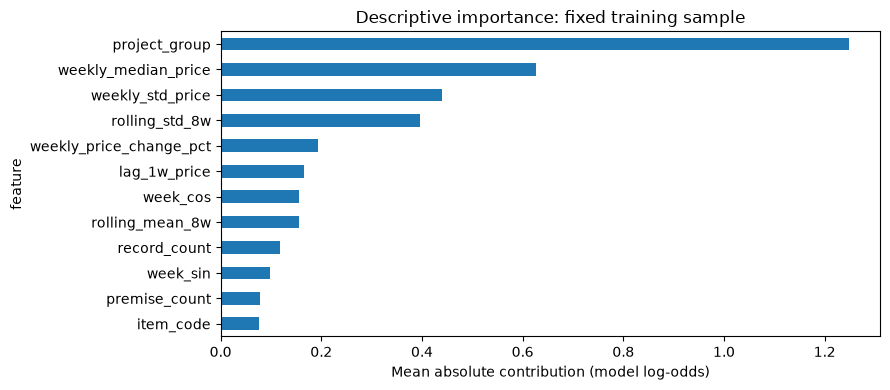

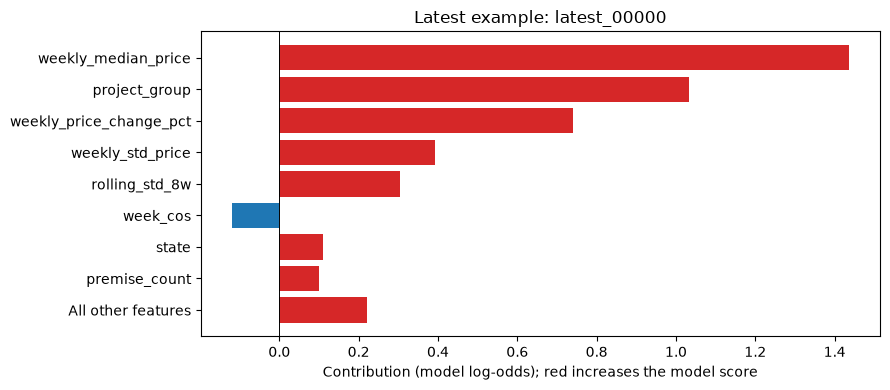

Baseline -1.6670 + all contributions = raw output 2.5476; model score 0.9274.
Saved dashboard inputs and explanations to: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/08_explanations


In [7]:
read_started = perf_counter()
dashboard = pd.read_parquet(OUTPUT_DIR / CACHE_FILES[0])
explanations = pd.read_parquet(OUTPUT_DIR / CACHE_FILES[1])
importance = pd.read_csv(OUTPUT_DIR / CACHE_FILES[2])
cache_read_ms = 1000 * (perf_counter() - read_started)
SHAP_COLUMNS = ["shap__" + name for name in FEATURES]
np.testing.assert_allclose(explanations.base_value + explanations[SHAP_COLUMNS].sum(axis=1), explanations.raw_output, rtol=1e-5, atol=1e-5)
linked_scores = explanations.raw_output if family == "Random Forest" else expit(explanations.raw_output)
np.testing.assert_allclose(linked_scores, explanations.model_score, rtol=1e-5, atol=1e-6)
latest_explanations = explanations.loc[explanations.cohort.eq("latest")].set_index("explanation_id")
assert dashboard.forecast_id.is_unique and explanations.explanation_id.is_unique
assert dashboard.has_cached_explanation.eq(dashboard.forecast_id.isin(latest_explanations.index)).all()
np.testing.assert_allclose(dashboard.set_index("forecast_id").loc[latest_explanations.index, "model_score"], latest_explanations.model_score, rtol=1e-6, atol=1e-8)
print("Verified additive explanations. No model was fitted or reselected.")
print(f"Cached latest explanations: {len(latest_explanations):,} / {len(dashboard):,} supported rows")
print(f"Original offline build: {cache_manifest['offline_cache_build_seconds']:.2f} s | Current three-file read: {cache_read_ms:.2f} ms")
print("File-read timing is not a measurement of dashboard/browser responsiveness.")
display(dashboard[IDENTIFIERS + ["model_score", "predicted_surge", "anomaly_score", "is_anomaly", "has_cached_explanation"]].head(10))
display(importance)
fig, ax = plt.subplots(figsize=(9, 4))
importance.head(12).iloc[::-1].plot.barh(x="feature", y="mean_abs_shap", legend=False, ax=ax)
ax.set(xlabel=f"Mean absolute contribution ({units})", title="Descriptive importance: fixed training sample")
fig.tight_layout(); plt.show()
if len(latest_explanations):
    case = latest_explanations.iloc[0]
    contributions = pd.Series(case[SHAP_COLUMNS].to_numpy(dtype=float), index=FEATURES)
    chosen = contributions.abs().nlargest(8).index
    shown = contributions.loc[chosen].copy()
    shown.loc["All other features"] = contributions.drop(chosen).sum()
    shown = shown.iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(shown.index, shown.values, color=np.where(shown.values >= 0, "tab:red", "tab:blue"))
    ax.axvline(0, color="black", linewidth=.7)
    ax.set(xlabel=f"Contribution ({units}); red increases the model score", title=f"Latest example: {case.name}")
    fig.tight_layout(); plt.show()
    print(f"Baseline {case.base_value:.4f} + all contributions = raw output {case.raw_output:.4f}; model score {case.model_score:.4f}.")
else:
    print("No supported latest rows/explanations. No older forecasts were substituted.")
print("Saved dashboard inputs and explanations to:", OUTPUT_DIR)


## Handoff to the dashboard
Four files are saved under this run's `08_explanations/`: `latest_dashboard.parquet`, `shap_explanations.parquet`, `training_feature_importance.csv` and `explanation_manifest.json`. The dashboard can read these offline artifacts without fitting models or calculating SHAP on each click. It must explicitly show when an explanation is unavailable; that does not mean low risk.

Keep the forecasting score, anomaly flag and source-quality concerns separate. Show the data week, supported population, false-alert limitations and uncalibrated-score label. Grouped feature contributions depend on the model, background/path reference and correlated features; they do not establish fuel, weather, exchange-rate or policy effects absent from the inputs.

The cache timings measure local file work only. Actual serving latency, user comprehension, accessibility and stakeholder usefulness require dashboard evaluation. SHAP does not demonstrate adoption, affordability improvements or reductions in inequality. Preserve the frozen 06 choice/cutoff and 07 detector while building the dashboard.